<a href="https://colab.research.google.com/github/munizgui/GS2_SERS_1CCA/blob/main/citizen_assist_ai_energia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Citizen Assist AI — Soluções em Energias Renováveis e Sustentáveis (FIAP - 1CCA)
**Contexto:** Módulo de apoio à decisão energética para famílias residenciais urbanas (referência: São Paulo/SP), comparando **Eficiência Energética** e **Energia Solar Fotovoltaica** frente ao consumo atual.

In [1]:
!pip install -q google-genai pandas matplotlib

In [2]:
import json
from dataclasses import dataclass, asdict
from typing import Dict, Any
import pandas as pd

# Dados públicos e premissas verificáveis
PUBLIC_DATA = {
    "tarifa_media_kwh": 0.85,          # R$/kWh - Ref: ANEEL (média residencial SP c/ impostos)
    "irradiacao_solar_sp": 4.45,       # kWh/m²/dia - Ref: CRESESB / INPE
    "performance_ratio_solar": 0.78,   # Eficiência global estimada do sistema fotovoltaico
    "fator_emissao_co2": 0.0385,       # kg CO2/kWh - Ref: MCTI (SIN)
    "custo_kwp_instalado": 4000.00,    # R$/kWp - Média de mercado residencial
    "custo_eficiencia_kit": 250.00,    # R$ - Lâmpadas LED + ajustes básicos
}

@dataclass
class EnergyComparisonResult:
    consumo_mensal_kwh: float
    gasto_mensal_atual: float
    gasto_anual_atual: float
    alternativa_1_eficiencia: Dict[str, Any]
    alternativa_2_solar: Dict[str, Any]
    referencias: list
    limitacoes: list

def calcular_alternativas_energeticas(
    consumo_mensal_kwh: float,
    tarifa_kwh: float = PUBLIC_DATA["tarifa_media_kwh"],
    possui_telhado_proprio: bool = True
) -> Dict[str, Any]:
    """
    Compara o cenário atual com Eficiência Energética e Energia Solar Fotovoltaica
    nos horizontes de 1 ano e 5 anos.
    """
    if consumo_mensal_kwh <= 0:
        raise ValueError("O consumo mensal em kWh deve ser maior que zero.")

    gasto_mensal_atual = round(consumo_mensal_kwh * tarifa_kwh, 2)
    gasto_anual_atual = round(gasto_mensal_atual * 12, 2)

    # Alternativa 1: Eficiência Energética (redução estimada de 21,4%)
    economia_kwh_mes_alt1 = round(consumo_mensal_kwh * 0.214, 1)
    economia_kwh_ano_alt1 = round(economia_kwh_mes_alt1 * 12, 1)
    economia_anual_rs_alt1 = round(economia_kwh_ano_alt1 * tarifa_kwh, 2)
    investimento_alt1 = PUBLIC_DATA["custo_eficiencia_kit"]
    payback_meses_alt1 = round((investimento_alt1 / (economia_anual_rs_alt1 / 12)), 1)
    co2_evitado_5anos_alt1 = round(economia_kwh_ano_alt1 * 5 * PUBLIC_DATA["fator_emissao_co2"], 2)

    # Alternativa 2: Solar Fotovoltaica On-Grid
    alvo_geracao_mensal = max(consumo_mensal_kwh - 50, consumo_mensal_kwh * 0.65)
    potencia_kwp = round(
        alvo_geracao_mensal / (PUBLIC_DATA["irradiacao_solar_sp"] * 30 * PUBLIC_DATA["performance_ratio_solar"]),
        2
    )
    potencia_kwp = max(potencia_kwp, 1.1)

    geracao_mensal_kwh = round(
        potencia_kwp * PUBLIC_DATA["irradiacao_solar_sp"] * 30 * PUBLIC_DATA["performance_ratio_solar"],
        1
    )
    geracao_anual_kwh = round(geracao_mensal_kwh * 12, 1)
    economia_anual_rs_alt2 = round(geracao_anual_kwh * tarifa_kwh * 0.88, 2)  # Desconto Fio B (Lei 14.300)
    investimento_alt2 = round(potencia_kwp * PUBLIC_DATA["custo_kwp_instalado"], 2)
    payback_anos_alt2 = round(investimento_alt2 / economia_anual_rs_alt2, 1)
    co2_evitado_5anos_alt2 = round(geracao_anual_kwh * 5 * PUBLIC_DATA["fator_emissao_co2"], 2)

    recomendacao = (
        "Iniciar imediatamente pela Alternativa 1 (Eficiência Energética) e planejar a "
        "Alternativa 2 (Solar Fotovoltaica), pois o imóvel possui telhado próprio."
        if possui_telhado_proprio
        else "Priorizar a Alternativa 1 (Eficiência Energética), pois a ausência de telhado "
             "próprio inviabiliza a instalação fotovoltaica individual tradicional."
    )

    resultado = EnergyComparisonResult(
        consumo_mensal_kwh=consumo_mensal_kwh,
        gasto_mensal_atual=gasto_mensal_atual,
        gasto_anual_atual=gasto_anual_atual,
        alternativa_1_eficiencia={
            "nome": "Eficiência Energética",
            "investimento_rs": investimento_alt1,
            "energia_economizada_ano_kwh": economia_kwh_ano_alt1,
            "economia_anual_rs": economia_anual_rs_alt1,
            "saldo_liquido_5_anos_rs": round((economia_anual_rs_alt1 * 5) - investimento_alt1, 2),
            "payback": f"{payback_meses_alt1} meses",
            "co2_evitado_5_anos_kg": co2_evitado_5anos_alt1,
            "viabilidade": "Alta (casas e apartamentos)",
        },
        alternativa_2_solar={
            "nome": f"Solar Fotovoltaica ({potencia_kwp} kWp)",
            "investimento_rs": investimento_alt2,
            "energia_gerada_ano_kwh": geracao_anual_kwh,
            "economia_anual_rs": economia_anual_rs_alt2,
            "saldo_liquido_5_anos_rs": round((economia_anual_rs_alt2 * 5) - investimento_alt2, 2),
            "payback": f"{payback_anos_alt2} anos",
            "co2_evitado_5_anos_kg": co2_evitado_5anos_alt2,
            "viabilidade": "Alta (telhado próprio)" if possui_telhado_proprio else "Inviável no local (sem telhado)",
        },
        referencias=[
            "ANEEL - Tarifas Residenciais Médias (SP)",
            "CRESESB / INPE - Atlas Brasileiro de Energia Solar (4,45 kWh/m²/dia)",
            "EPE / PROCEL - Balanço Energético Nacional",
            "MCTI - Fatores de Emissão de CO2 do SIN",
        ],
        limitacoes=[
            "Valores são estimativas médias e não garantias contratuais.",
            "A geração solar varia conforme sombreamento, inclinação do telhado e clima.",
            "Sujeito às regras da Lei 14.300/2022 (Fio B) e reajustes tarifários.",
        ],
    )

    payload = asdict(resultado)
    payload["recomendacao_contextual"] = recomendacao
    return payload

# Simulação para o caso de referência: 350 kWh/mês
dados_base = calcular_alternativas_energeticas(350, possui_telhado_proprio=True)

df_comparativo = pd.DataFrame([
    {
        "Cenário": "Cenário Base (Atual)",
        "Investimento (R$)": 0.00,
        "Energia Poupad/Gerada (kWh/ano)": 0.0,
        "Economia Anual (R$)": 0.00,
        "Saldo Líquido 5 Anos (R$)": 0.00,
        "Payback": "-",
        "CO2 Evitado 5 Anos (kg)": 0.0,
    },
    {
        "Cenário": dados_base["alternativa_1_eficiencia"]["nome"],
        "Investimento (R$)": dados_base["alternativa_1_eficiencia"]["investimento_rs"],
        "Energia Poupad/Gerada (kWh/ano)": dados_base["alternativa_1_eficiencia"]["energia_economizada_ano_kwh"],
        "Economia Anual (R$)": dados_base["alternativa_1_eficiencia"]["economia_anual_rs"],
        "Saldo Líquido 5 Anos (R$)": dados_base["alternativa_1_eficiencia"]["saldo_liquido_5_anos_rs"],
        "Payback": dados_base["alternativa_1_eficiencia"]["payback"],
        "CO2 Evitado 5 Anos (kg)": dados_base["alternativa_1_eficiencia"]["co2_evitado_5_anos_kg"],
    },
    {
        "Cenário": dados_base["alternativa_2_solar"]["nome"],
        "Investimento (R$)": dados_base["alternativa_2_solar"]["investimento_rs"],
        "Energia Poupad/Gerada (kWh/ano)": dados_base["alternativa_2_solar"]["energia_gerada_ano_kwh"],
        "Economia Anual (R$)": dados_base["alternativa_2_solar"]["economia_anual_rs"],
        "Saldo Líquido 5 Anos (R$)": dados_base["alternativa_2_solar"]["saldo_liquido_5_anos_rs"],
        "Payback": dados_base["alternativa_2_solar"]["payback"],
        "CO2 Evitado 5 Anos (kg)": dados_base["alternativa_2_solar"]["co2_evitado_5_anos_kg"],
    }
])

display(df_comparativo)

,Cenário,Investimento (R$),Energia Poupad/Gerada (kWh/ano),Economia Anual (R$),Saldo Líquido 5 Anos (R$),Payback,CO2 Evitado 5 Anos (kg)
0,Cenário Base (Atual),0.0,0.0,0.00,0.0,-,0.00
1,Eficiência Energética,250.0,898.8,763.98,3569.9,3.9 meses,173.02
2,Solar Fotovoltaica (2.88 kWp),11520.0,3598.8,2691.90,1939.5,4.3 anos,692.77


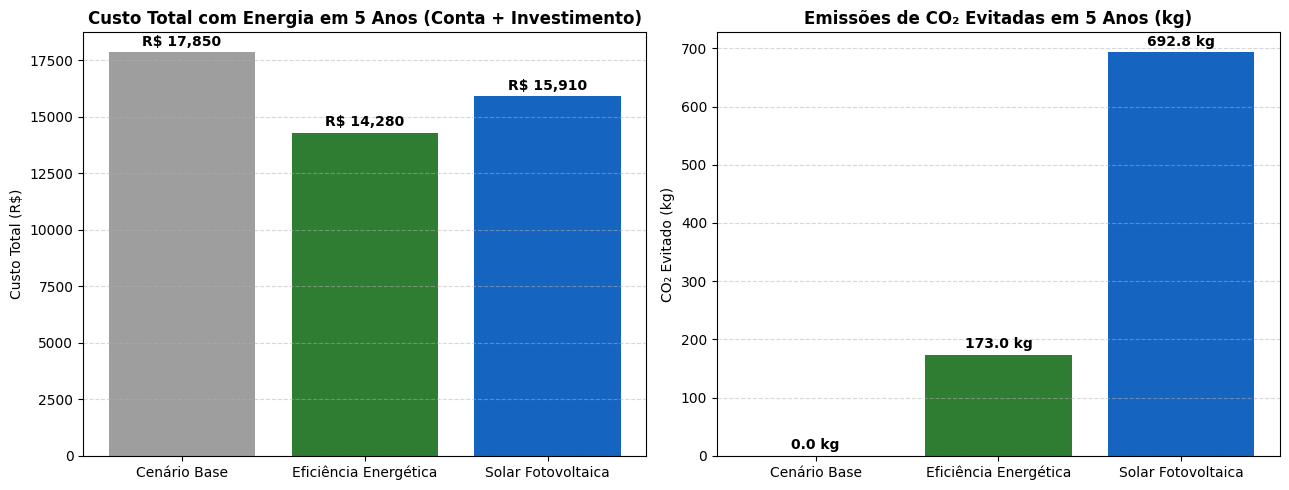

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cenarios = ["Cenário Base", "Eficiência Energética", "Solar Fotovoltaica"]
cores = ["#9e9e9e", "#2e7d32", "#1565c0"]

gasto_5_anos = [
    dados_base["gasto_anual_atual"] * 5,
    (dados_base["gasto_anual_atual"] - dados_base["alternativa_1_eficiencia"]["economia_anual_rs"]) * 5
    + dados_base["alternativa_1_eficiencia"]["investimento_rs"],
    (dados_base["gasto_anual_atual"] - dados_base["alternativa_2_solar"]["economia_anual_rs"]) * 5
    + dados_base["alternativa_2_solar"]["investimento_rs"],
]

bars1 = axes[0].bar(cenarios, gasto_5_anos, color=cores)
axes[0].set_title("Custo Total com Energia em 5 Anos (Conta + Investimento)", fontweight="bold")
axes[0].set_ylabel("Custo Total (R$)")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 300, f"R$ {yval:,.0f}", ha="center", fontweight="bold")

co2_evitado = [
    0,
    dados_base["alternativa_1_eficiencia"]["co2_evitado_5_anos_kg"],
    dados_base["alternativa_2_solar"]["co2_evitado_5_anos_kg"],
]

bars2 = axes[1].bar(cenarios, co2_evitado, color=cores)
axes[1].set_title("Emissões de CO₂ Evitadas em 5 Anos (kg)", fontweight="bold")
axes[1].set_ylabel("CO₂ Evitado (kg)")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 12, f"{yval:.1f} kg", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [4]:
import os
from google import genai
from google.genai import types

SYSTEM_PROMPT_ENERGIA = """
Você é o módulo de Energia e Sustentabilidade do Citizen Assist AI.
Sua função é orientar cidadãos sobre consumo consciente, eficiência energética e fontes renováveis
com linguagem clara, acessível e tecnicamente fundamentada.

REGRAS OBRIGATÓRIAS:
1. Utilize sempre a ferramenta `calcular_alternativas_energeticas` para fundamentar seus números.
2. Compare explicitamente o cenário atual com as duas alternativas (Eficiência Energética e Solar Fotovoltaica), destacando custos, economia em R$ e kWh, payback e impacto ambiental (CO2 evitado).
3. Adapte a recomendação à realidade do usuário (ex.: apartamento alugado vs. casa própria).
4. Cite as referências utilizadas (ANEEL, CRESESB/INPE, EPE/PROCEL e MCTI).
5. Nunca trate estimativas como garantias; inclua sempre as condições e limitações das estimativas.
"""

def citizen_assist_energia(pergunta_usuario: str, consumo_kwh: float, possui_telhado: bool) -> str:
    api_key = None
    try:
        from google.colab import userdata
        api_key = userdata.get("GEMINI_API_KEY")
    except Exception:
        api_key = os.environ.get("GEMINI_API_KEY")

    if api_key:
        client = genai.Client(api_key=api_key)
        prompt_contextualizado = (
            f"Pergunta do cidadão: {pergunta_usuario}\n"
            f"Dados informados pelo usuário: consumo_mensal_kwh={consumo_kwh}, "
            f"possui_telhado_proprio={possui_telhado}."
        )
        response = client.models.generate_content(
            model="gemini-2.5-flash",
            contents=prompt_contextualizado,
            config=types.GenerateContentConfig(
                system_instruction=SYSTEM_PROMPT_ENERGIA,
                tools=[calcular_alternativas_energeticas],
                temperature=0.3,
            ),
        )
        return response.text

    # Fallback determinístico caso a chave não esteja configurada no ambiente de avaliação
    calc = calcular_alternativas_energeticas(consumo_kwh, possui_telhado_proprio=possui_telhado)
    alt1 = calc["alternativa_1_eficiencia"]
    alt2 = calc["alternativa_2_solar"]

    return (
        f"### Orientação Energética — Citizen Assist AI\n\n"
        f"**Análise do seu cenário atual:** Com um consumo de **{calc['consumo_mensal_kwh']} kWh/mês**, "
        f"seu gasto estimado é de **R$ {calc['gasto_mensal_atual']:.2f}/mês** (R$ {calc['gasto_anual_atual']:.2f}/ano).\n\n"
        f"**Comparação de Alternativas:**\n"
        f"1. **{alt1['nome']}:** Investimento inicial estimado de **R$ {alt1['investimento_rs']:.2f}**, "
        f"gerando economia de **{alt1['energia_economizada_ano_kwh']} kWh/ano** (~R$ {alt1['economia_anual_rs']:.2f}/ano), "
        f"retorno em **{alt1['payback']}** e redução de **{alt1['co2_evitado_5_anos_kg']} kg de CO₂** em 5 anos.\n"
        f"2. **{alt2['nome']}:** Investimento estimado de **R$ {alt2['investimento_rs']:.2f}**, "
        f"geração de **{alt2['energia_gerada_ano_kwh']} kWh/ano** (~R$ {alt2['economia_anual_rs']:.2f}/ano de economia líquida), "
        f"retorno em **{alt2['payback']}** e redução de **{alt2['co2_evitado_5_anos_kg']} kg de CO₂** em 5 anos. "
        f"*(Viabilidade: {alt2['viabilidade']})*\n\n"
        f"**Recomendação:** {calc['recomendacao_contextual']}\n\n"
        f"**Condições e Limitações:**\n"
        + "\n".join([f"- {lim}" for lim in calc["limitacoes"]])
        + "\n\n**Fontes Utilizadas:** " + ", ".join(calc["referencias"])
    )

In [5]:
from IPython.display import display, Markdown

print("=== TESTE 1: Morador de Casa Própria (350 kWh/mês) ===")
resposta_1 = citizen_assist_energia(
    pergunta_usuario="Minha conta de luz vem quase R$ 300 por mês. Vale mais a pena trocar lâmpadas/hábitos ou colocar energia solar?",
    consumo_kwh=350,
    possui_telhado=True
)
display(Markdown(resposta_1))

print("\n" + "="*70 + "\n")

print("=== TESTE 2: Morador de Apartamento Alugado (220 kWh/mês) ===")
resposta_2 = citizen_assist_energia(
    pergunta_usuario="Moro de aluguel em apartamento e quero reduzir minha conta de energia. O que você recomenda?",
    consumo_kwh=220,
    possui_telhado=False
)
display(Markdown(resposta_2))

=== TESTE 1: Morador de Casa Própria (350 kWh/mês) ===


### Orientação Energética — Citizen Assist AI

**Análise do seu cenário atual:** Com um consumo de **350 kWh/mês**, seu gasto estimado é de **R$ 297.50/mês** (R$ 3570.00/ano).

**Comparação de Alternativas:**
1. **Eficiência Energética:** Investimento inicial estimado de **R$ 250.00**, gerando economia de **898.8 kWh/ano** (~R$ 763.98/ano), retorno em **3.9 meses** e redução de **173.02 kg de CO₂** em 5 anos.
2. **Solar Fotovoltaica (2.88 kWp):** Investimento estimado de **R$ 11520.00**, geração de **3598.8 kWh/ano** (~R$ 2691.90/ano de economia líquida), retorno em **4.3 anos** e redução de **692.77 kg de CO₂** em 5 anos. *(Viabilidade: Alta (telhado próprio))*

**Recomendação:** Iniciar imediatamente pela Alternativa 1 (Eficiência Energética) e planejar a Alternativa 2 (Solar Fotovoltaica), pois o imóvel possui telhado próprio.

**Condições e Limitações:**
- Valores são estimativas médias e não garantias contratuais.
- A geração solar varia conforme sombreamento, inclinação do telhado e clima.
- Sujeito às regras da Lei 14.300/2022 (Fio B) e reajustes tarifários.

**Fontes Utilizadas:** ANEEL - Tarifas Residenciais Médias (SP), CRESESB / INPE - Atlas Brasileiro de Energia Solar (4,45 kWh/m²/dia), EPE / PROCEL - Balanço Energético Nacional, MCTI - Fatores de Emissão de CO2 do SIN



=== TESTE 2: Morador de Apartamento Alugado (220 kWh/mês) ===


### Orientação Energética — Citizen Assist AI

**Análise do seu cenário atual:** Com um consumo de **220 kWh/mês**, seu gasto estimado é de **R$ 187.00/mês** (R$ 2244.00/ano).

**Comparação de Alternativas:**
1. **Eficiência Energética:** Investimento inicial estimado de **R$ 250.00**, gerando economia de **565.2 kWh/ano** (~R$ 480.42/ano), retorno em **6.2 meses** e redução de **108.8 kg de CO₂** em 5 anos.
2. **Solar Fotovoltaica (1.63 kWp):** Investimento estimado de **R$ 6520.00**, geração de **2036.4 kWh/ano** (~R$ 1523.23/ano de economia líquida), retorno em **4.3 anos** e redução de **392.01 kg de CO₂** em 5 anos. *(Viabilidade: Inviável no local (sem telhado))*

**Recomendação:** Priorizar a Alternativa 1 (Eficiência Energética), pois a ausência de telhado próprio inviabiliza a instalação fotovoltaica individual tradicional.

**Condições e Limitações:**
- Valores são estimativas médias e não garantias contratuais.
- A geração solar varia conforme sombreamento, inclinação do telhado e clima.
- Sujeito às regras da Lei 14.300/2022 (Fio B) e reajustes tarifários.

**Fontes Utilizadas:** ANEEL - Tarifas Residenciais Médias (SP), CRESESB / INPE - Atlas Brasileiro de Energia Solar (4,45 kWh/m²/dia), EPE / PROCEL - Balanço Energético Nacional, MCTI - Fatores de Emissão de CO2 do SIN